# Domain decomposition: cPINN / XPINN on a composite rod

One network per subdomain, glued by **interface losses**. The benchmark is
steady heat conduction through a two-material rod — the classic composite
wall:

$$\frac{d}{dx}\Big(k(x)\,\frac{du}{dx}\Big) = 0,\qquad
  k(x)=\begin{cases}k_1 & x<\gamma\\ k_2 & x\ge\gamma\end{cases},\qquad
  u(0)=1,\; u(1)=0 .$$

The exact solution is piecewise linear with a **kink** at the interface
$\gamma$ (temperature continuous, gradient jumps so that the flux
$q=-k\,u'$ is continuous). Section 2 shows that a single network trained on
the strong residual does not even *see* the material jump; two subdomain
networks with the physical interface conditions

$$u_1(\gamma)=u_2(\gamma), \qquad k_1 u_1'(\gamma)=k_2 u_2'(\gamma)$$

represent it exactly. This is the cPINN interface (conservative quantities
matched); XPINN generalizes the same idea to arbitrary space-time
decompositions.

The prose describes the **default** run. Change the values below and *Run All*;
every figure and printout follows. Checks that quote slide numbers are skipped
when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
SEED = 0
K1, K2, GAMMA = 1.0, 5.0, 0.5   # conductivities and interface position
N_SIDE = 80                     # collocation points per material
WIDTH_SINGLE, WIDTH_SUB = 32, 24
W_BC, W_CONT, W_FLUX = 100.0, 100.0, 10.0   # loss weights: boundary, state continuity, flux
STEPS, LR = 4000, 2e-3
# --------------------------------------------------------------------------

DEFAULTS = dict(SEED=0, K1=1.0, K2=5.0, GAMMA=0.5, N_SIDE=80, WIDTH_SINGLE=32, WIDTH_SUB=24,
                W_BC=100.0, W_CONT=100.0, W_FLUX=10.0, STEPS=4000, LR=2e-3)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))
import numpy as np
import torch
import matplotlib.pyplot as plt
from pyutils import set_plot_style, save_dual, fg
from pyutils.pinn_core import MLP, grad, train
set_plot_style()
torch.set_default_dtype(torch.float64)
torch.manual_seed(SEED); np.random.seed(SEED)

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

## 1. Exact solution

With no source the flux $q$ is constant. Total thermal resistance
$R=\gamma/k_1+(1-\gamma)/k_2$ gives $q=\Delta u/R$, and $u$ is linear in
each material with slope $-q/k$.

In [3]:
k1, k2, gam = K1, K2, GAMMA
R = gam/k1 + (1-gam)/k2
q = (1.0 - 0.0)/R                      # flux, here 1/0.6
u_gamma = 1.0 - q*gam/k1               # interface temperature

def u_exact(x):
    x = np.asarray(x)
    return np.where(x < gam, 1.0 - q*x/k1, u_gamma - q*(x-gam)/k2)

print(f"flux q = {q:.4f}, interface temperature u({gam}) = {u_gamma:.4f}")
assert abs(u_exact(1.0)) < 1e-12

flux q = 1.6667, interface temperature u(0.5) = 0.1667


## 2. Baseline: one smooth network for the whole rod

The strong-form residual needs $k(x)$ under the derivative. With piecewise-
constant $k$ this is $k(x)\,u''=0$ away from the interface, so the loss below
is $u''=0$ on each side plus the two boundary values. **No term contains $k$.**
The conductivity jump would only enter through $k'(x)$, a delta at $\gamma$
that no collocation point ever sees. The straight line $u=1-x$ satisfies every
term of this loss exactly — so that is what a single network will find, with a
near-zero loss and the wrong answer.

In [4]:
x1 = torch.linspace(0.01, gam-0.01, N_SIDE).reshape(-1, 1).requires_grad_(True)
x2 = torch.linspace(gam+0.01, 0.99, N_SIDE).reshape(-1, 1).requires_grad_(True)
xb = torch.tensor([[0.0], [1.0]])
ub = torch.tensor([[1.0], [0.0]])

net_single = MLP([1, WIDTH_SINGLE, WIDTH_SINGLE, 1])

def loss_single():
    r1 = grad(grad(net_single(x1), x1), x1)          # u'' = 0 in material 1
    r2 = grad(grad(net_single(x2), x2), x2)          # u'' = 0 in material 2
    lb = ((net_single(xb) - ub)**2).mean()
    return (r1**2).mean() + (r2**2).mean() + W_BC*lb

hist_single = train(loss_single, net_single.parameters(), steps=STEPS, lr=LR)
print(f"single-domain final loss {hist_single[-1]:.3e}")

single-domain final loss 2.778e-05


## 3. cPINN/XPINN: one network per material + interface losses

Two small networks $u_1,u_2$; the loss adds the two physical interface
conditions at $x=\gamma$. Note the flux condition carries the conductivities
— this is where the physics of the interface lives.

In [5]:
netA, netB = MLP([1, WIDTH_SUB, WIDTH_SUB, 1]), MLP([1, WIDTH_SUB, WIDTH_SUB, 1])
xg = torch.tensor([[gam]], requires_grad=True)

def loss_xpinn():
    rA = grad(grad(netA(x1), x1), x1)
    rB = grad(grad(netB(x2), x2), x2)
    lb = ((netA(xb[:1]) - ub[:1])**2 + (netB(xb[1:]) - ub[1:])**2).mean()
    # interface: continuity of u and of the flux k*u'
    uA, uB = netA(xg), netB(xg)
    dA, dB = grad(uA, xg), grad(uB, xg)
    l_cont = ((uA - uB)**2).mean()
    l_flux = ((k1*dA - k2*dB)**2).mean()
    return (rA**2).mean() + (rB**2).mean() + W_BC*lb + W_CONT*l_cont + W_FLUX*l_flux

params = list(netA.parameters()) + list(netB.parameters())
hist_x = train(loss_xpinn, params, steps=STEPS, lr=LR)
print(f"decomposed final loss {hist_x[-1]:.3e}")

decomposed final loss 3.662e-03


## 4. Compare

The single network reaches a tiny loss but converges to $u=1-x$: it solved a
different problem, one without the material interface. Its error is largest at
$\gamma$, where the true solution has its kink. The decomposed model carries
the physics of the interface (continuity of $u$ and of the flux $k\,u'$) in its
loss and is accurate everywhere; each of its networks only has to represent a
straight line.

*Reading the error plot.* It shows $|u-u_{\text{exact}}|$ on a log axis. Where
the error passes through zero (a sign change) or just touches it, the log axis
draws a deep notch. The notches are not special points of the solution; they
only mark where the network happens to cross the exact curve.

max error  single: 3.32e-01   decomposed: 6.00e-04
single PINN vs the line 1 - x: max difference 1.2e-04


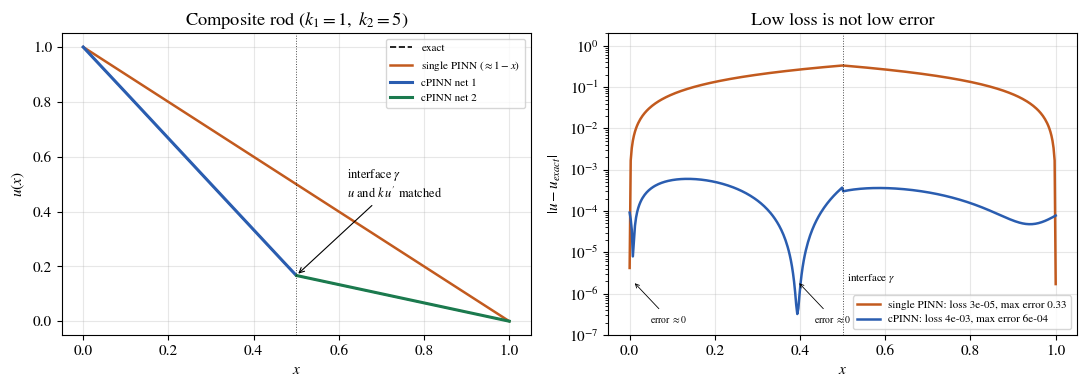

In [6]:
xs = np.linspace(0, 1, 400)
with torch.no_grad():
    u_s = net_single(torch.tensor(xs.reshape(-1, 1))).numpy().ravel()
u_x = np.empty_like(xs)
mask = xs < gam
with torch.no_grad():
    u_x[mask] = netA(torch.tensor(xs[mask].reshape(-1, 1))).numpy().ravel()
    u_x[~mask] = netB(torch.tensor(xs[~mask].reshape(-1, 1))).numpy().ravel()
ue = u_exact(xs)
err_s, err_x = np.abs(u_s - ue), np.abs(u_x - ue)
print(f"max error  single: {err_s.max():.2e}   decomposed: {err_x.max():.2e}")
print(f"single PINN vs the line 1 - x: max difference {np.abs(u_s - (1 - xs)).max():.1e}")
assert err_x.max() < err_s.max() / 3, "decomposition should win at the kink"
assert hist_single[-1] < 1e-3 and err_s.max() > 0.2, "single PINN: low loss, large error"
assert np.abs(u_s - (1 - xs)).max() < 0.02, "the single PINN converges to the line 1 - x"
# near-zeros of the decomposed error (local minima far below its maximum):
# these are the notches on the log-scale plot
e_abs = np.abs(u_x - ue)
is_min = (e_abs[1:-1] < e_abs[:-2]) & (e_abs[1:-1] < e_abs[2:]) & (e_abs[1:-1] < 0.05 * e_abs.max())
notches = xs[1:-1][is_min]

def plot_xpinn_heat():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(xs, ue, color=fg(), lw=1.2, ls='--', label='exact')
    ax[0].plot(xs, u_s, color='C1', lw=1.8, label='single PINN ($\\approx 1-x$)')
    ax[0].plot(xs[mask], u_x[mask], color='C0', lw=2.2, label='cPINN net 1')
    ax[0].plot(xs[~mask], u_x[~mask], color='C2', lw=2.2, label='cPINN net 2')
    ax[0].axvline(gam, color=fg(), lw=0.7, ls=':', alpha=0.7)
    ax[0].annotate('interface $\\gamma$\n$u$ and $k\\,u\'$ matched',
                   (gam, u_gamma), (0.62, 0.45), fontsize=9,
                   arrowprops=dict(arrowstyle='->', color=fg(), lw=0.8))
    ax[0].set(xlabel='$x$', ylabel='$u(x)$',
              title=f'Composite rod ($k_1={k1:g},\\ k_2={k2:g}$)')
    ax[0].legend(fontsize=8)
    ax[1].semilogy(xs, err_s + 1e-12, color='C1', lw=1.8,
                   label=f'single PINN: loss {hist_single[-1]:.0e}, max error {err_s.max():.2f}')
    ax[1].semilogy(xs, err_x + 1e-12, color='C0', lw=1.8,
                   label=f'cPINN: loss {hist_x[-1]:.0e}, max error {err_x.max():.0e}')
    ax[1].axvline(gam, color=fg(), lw=0.7, ls=':', alpha=0.7)
    ax[1].text(gam + 0.01, 2e-6, 'interface $\\gamma$', fontsize=8, color=fg())
    for xn in notches:
        ax[1].annotate('error $\\approx 0$', (xn, 2e-6), (xn + 0.04, 2e-7), fontsize=7, color=fg(),
                       arrowprops=dict(arrowstyle='->', color=fg(), lw=0.6))
    ax[1].set(xlabel='$x$', ylabel='$|u - u_{exact}|$', ylim=(1e-7, 2),
              title='Low loss is not low error')
    ax[1].legend(fontsize=8)
    plt.tight_layout()

save_dual(plot_xpinn_heat, 'xpinn_heat', FIG)
plt.show()

## 5. What the interface losses do during training

/var/folders/px/kfx0kpc11td_5_f5ny95_wrh0000gn/T/ipykernel_74618/4151713885.py:13: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:837.)
  cont_hist.append(float(l_cont)); flux_hist.append(float(l_flux))


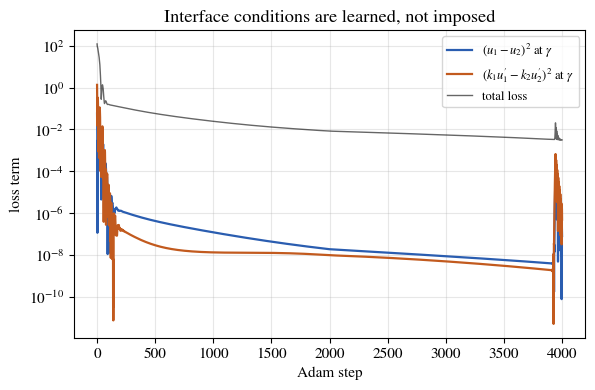

In [7]:
# track the two interface terms over a fresh run for the diagnostic figure
netA2, netB2 = MLP([1, WIDTH_SUB, WIDTH_SUB, 1]), MLP([1, WIDTH_SUB, WIDTH_SUB, 1])
cont_hist, flux_hist = [], []

def loss_tracked():
    rA = grad(grad(netA2(x1), x1), x1)
    rB = grad(grad(netB2(x2), x2), x2)
    lb = ((netA2(xb[:1]) - ub[:1])**2 + (netB2(xb[1:]) - ub[1:])**2).mean()
    uA, uB = netA2(xg), netB2(xg)
    dA, dB = grad(uA, xg), grad(uB, xg)
    l_cont = ((uA - uB)**2).mean()
    l_flux = ((k1*dA - k2*dB)**2).mean()
    cont_hist.append(float(l_cont)); flux_hist.append(float(l_flux))
    return (rA**2).mean() + (rB**2).mean() + W_BC*lb + W_CONT*l_cont + W_FLUX*l_flux

params2 = list(netA2.parameters()) + list(netB2.parameters())
hist2 = train(loss_tracked, params2, steps=STEPS, lr=LR)

def plot_xpinn_interface():
    fig, ax = plt.subplots(figsize=(6.6, 4))
    ax.semilogy(cont_hist, color='C0', lw=1.6, label='$(u_1-u_2)^2$ at $\\gamma$')
    ax.semilogy(flux_hist, color='C1', lw=1.6, label="$(k_1u_1'-k_2u_2')^2$ at $\\gamma$")
    ax.semilogy(hist2, color=fg(), lw=1.0, alpha=0.6, label='total loss')
    ax.set(xlabel='Adam step', ylabel='loss term',
           title='Interface conditions are learned, not imposed')
    ax.legend(fontsize=9)

save_dual(plot_xpinn_interface, 'xpinn_interface', FIG)
plt.show()

## Summary

* Domain decomposition gives each material its own network and puts the
  physics of the interface into the loss. Here that physics was exactly what
  the single-network loss was missing.
* The **flux** condition $k_1u_1'=k_2u_2'$ carries the conservation law
  across the cut — that is cPINN's defining ingredient; XPINN keeps the idea
  and generalizes the geometry (including time slabs, which is exactly the
  time-marching cure for the causality failure seen in the 3-DOF vessel).
* Cost: more networks and three extra loss weights — the usual PINN
  balancing act, now also at interfaces.

In [8]:
assert np.isfinite(hist2).all() and cont_hist[-1] < 1e-4 and flux_hist[-1] < 1e-4, "interface terms learned"
if AT_DEFAULTS:
    # numbers quoted on the slides and in notes/variants.tex
    assert abs(err_s.max() - 0.33) < 0.02 and err_x.max() < 1e-3, (err_s.max(), err_x.max())
    print(f'slide numbers: single loss {hist_single[-1]:.1e} / error {err_s.max():.2f}; '
          f'cPINN error {err_x.max():.0e}')
else:
    print('regression check skipped (parameters differ from the slide defaults)')

slide numbers: single loss 2.8e-05 / error 0.33; cPINN error 6e-04
